# CampusBites – Advanced Exploratory Data Analysis

## Day 2: Shop-wise Comparisons and Insights

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load master dataset
df = pd.read_csv("../data/processed/campusbites_master.csv")

print("Dataset loaded successfully!")
print("Total records:", len(df))

display(df.head())

Dataset loaded successfully!
Total records: 363


,Shop Name,Item to Buy,Price,Category
0,Annapurna,Plain Idli - 2 pc,40,South Indian
1,Annapurna,Masala Idli - 2 pc,45,South Indian
2,Annapurna,Wada - 2 pc,50,South Indian
3,Annapurna,Plain Dosa,45,South Indian
4,Annapurna,Onion Dosa,50,South Indian


## STEP 1 – SHOP-WISE FOOD CATEGORY COMPARISON

In [2]:
# Shop-wise food category comparison

shop_category = pd.crosstab(
    df["Shop Name"],
    df["Category"]
)

print("Food Category Distribution Across Shops:")
display(shop_category)

Food Category Distribution Across Shops:


Category,Beverages,Desserts,Fast Food,Main Course,Snacks,Soups,South Indian
Shop Name,,,,,,,
Annapurna,0,0,0,2,0,0,21
Appetite Rolls,0,0,30,0,0,0,0
Chai Garam,50,0,40,0,6,2,0
Food Court,2,1,8,34,9,0,28
Frisco,34,13,25,4,4,0,0
Tulips,9,28,8,2,2,0,1


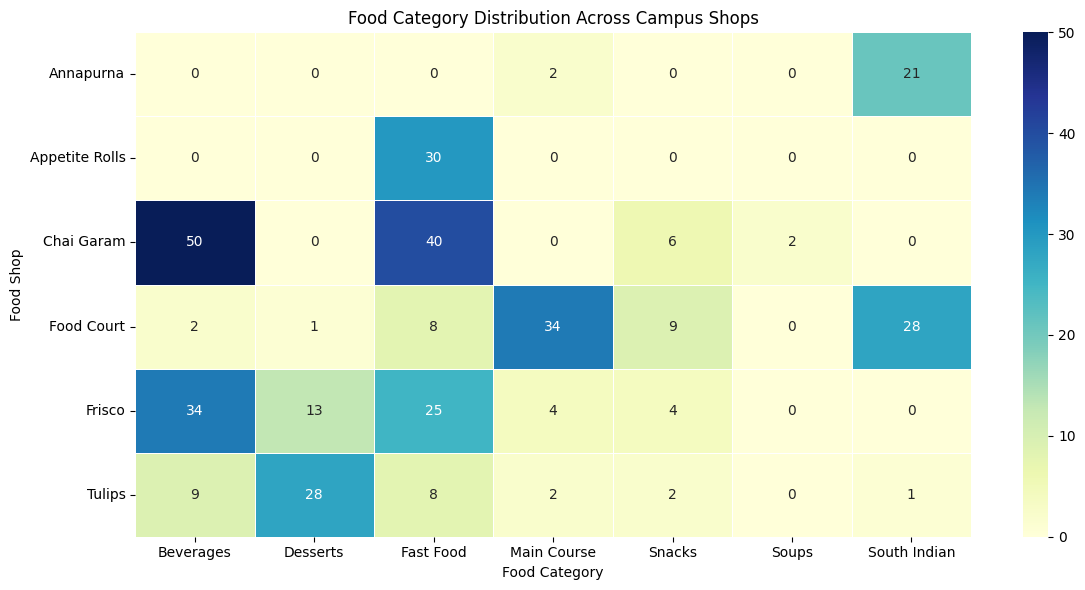

In [3]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    shop_category,
    annot=True,
    cmap="YlGnBu",
    fmt="d",
    linewidths=0.5
)

plt.title("Food Category Distribution Across Campus Shops")
plt.xlabel("Food Category")
plt.ylabel("Food Shop")

plt.tight_layout()
plt.show()

STEP 2 – MOST POPULAR FOOD CATEGORIES

In [4]:

# Count total items in each food category

category_counts = df["Category"].value_counts()

print("Most Popular Food Categories:")
display(category_counts)


Most Popular Food Categories:


Category
Fast Food       111
Beverages        95
South Indian     50
Main Course      42
Desserts         42
Snacks           21
Soups             2
Name: count, dtype: int64

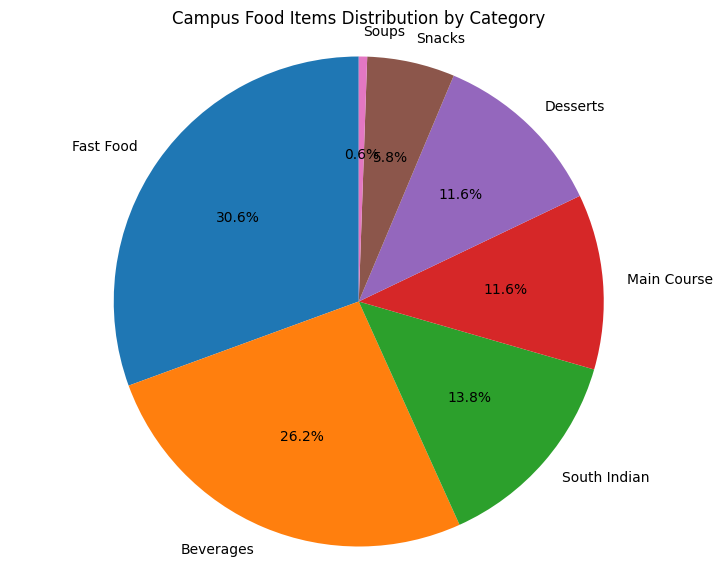

In [5]:

plt.figure(figsize=(9, 7))

plt.pie(
    category_counts,
    labels=category_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Campus Food Items Distribution by Category")
plt.axis("equal")

plt.show()


STEP 3 – CATEGORY-WISE PRICE ANALYSIS

In [6]:

# Calculate average price of each food category

category_prices = df.groupby("Category")["Price"].mean().sort_values(ascending=False)

print("Average Price by Food Category:")
display(category_prices)


Average Price by Food Category:


Category
Desserts        93.476190
Fast Food       83.234234
Main Course     76.666667
South Indian    63.300000
Beverages       58.473684
Snacks          48.428571
Soups           30.000000
Name: Price, dtype: float64

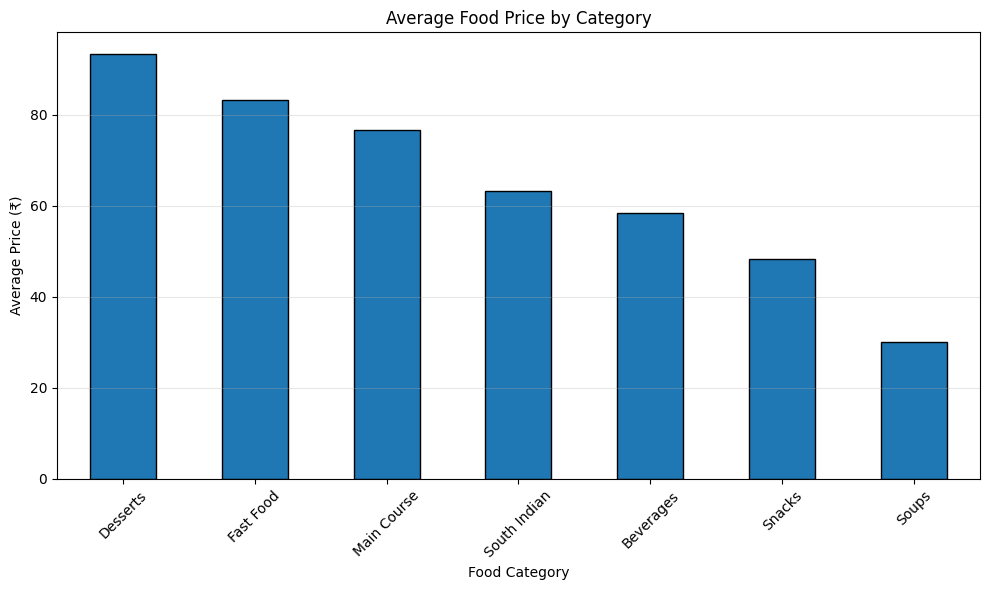

In [7]:

plt.figure(figsize=(10, 6))

category_prices.plot(kind="bar", edgecolor="black")

plt.title("Average Food Price by Category")
plt.xlabel("Food Category")
plt.ylabel("Average Price (₹)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [8]:
print("Most Expensive Category:")
print(category_prices.idxmax(), "₹", round(category_prices.max(), 2))

print("\nMost Affordable Category:")
print(category_prices.idxmin(), "₹", round(category_prices.min(), 2))

Most Expensive Category:
Desserts ₹ 93.48

Most Affordable Category:
Soups ₹ 30.0


STEP 4 – SHOP-WISE PRICE COMPARISON

In [9]:
# Calculate average price for each shop

shop_prices = df.groupby("Shop Name")["Price"].mean().sort_values(ascending=False)

print("Average Price Across Campus Shops:")
display(shop_prices)

Average Price Across Campus Shops:


Shop Name
Tulips            96.460000
Appetite Rolls    94.833333
Frisco            76.250000
Chai Garam        63.163265
Food Court        60.353659
Annapurna         55.434783
Name: Price, dtype: float64

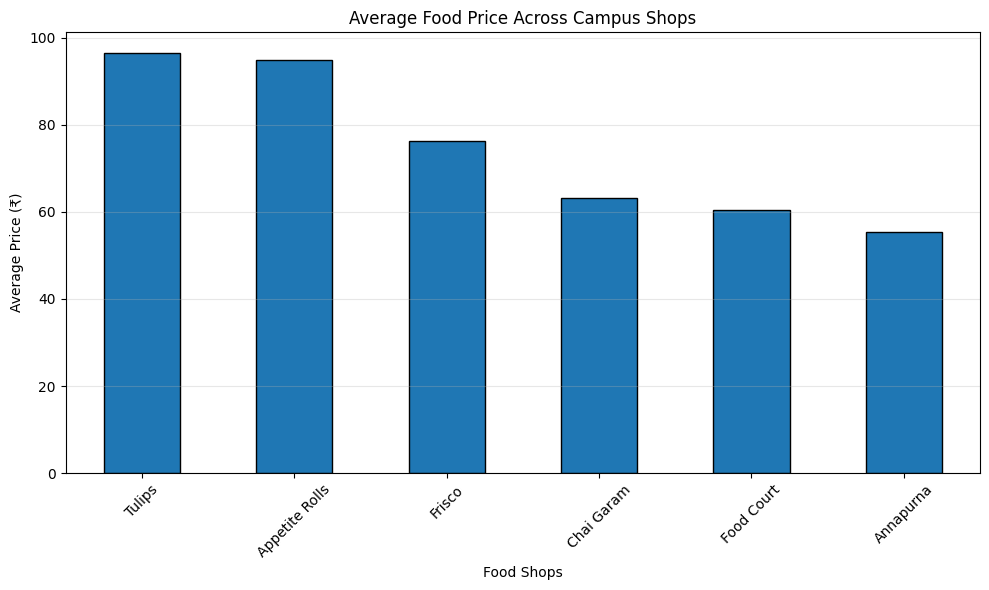

In [10]:
plt.figure(figsize=(10, 6))

shop_prices.plot(kind="bar", edgecolor="black")

plt.title("Average Food Price Across Campus Shops")
plt.xlabel("Food Shops")
plt.ylabel("Average Price (₹)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

STEP 5 – SHOP-WISE CATEGORY PRICE ANALYSIS

In [11]:

shop_category_prices = df.pivot_table(
    index="Shop Name",
    columns="Category",
    values="Price",
    aggfunc="mean"
)

print("Average Category Prices Across Shops:")
display(shop_category_prices.round(2))


Average Category Prices Across Shops:


Category,Beverages,Desserts,Fast Food,Main Course,Snacks,Soups,South Indian
Shop Name,,,,,,,
Annapurna,NaN,NaN,NaN,50.00,NaN,NaN,55.95
Appetite Rolls,NaN,NaN,94.83,NaN,NaN,NaN,NaN
Chai Garam,53.80,NaN,78.25,NaN,51.67,30.0,NaN
Food Court,18.50,20.00,48.12,65.88,36.89,NaN,69.11
Frisco,63.24,60.77,90.80,170.00,52.50,NaN,NaN
Tulips,75.33,111.29,76.12,100.00,82.50,NaN,55.00


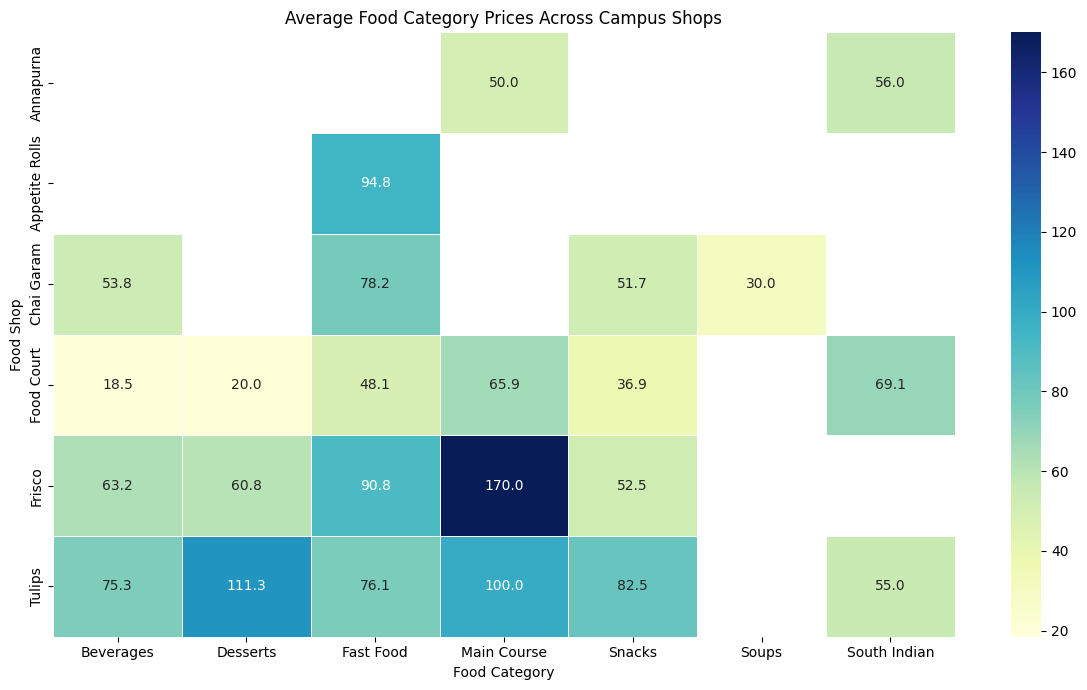

In [12]:

plt.figure(figsize=(12, 7))

sns.heatmap(
    shop_category_prices,
    annot=True,
    cmap="YlGnBu",
    fmt=".1f",
    linewidths=0.5
)

plt.title("Average Food Category Prices Across Campus Shops")
plt.xlabel("Food Category")
plt.ylabel("Food Shop")
plt.tight_layout()
plt.show()


STEP 6 – PRICE VARIABILITY ANALYSIS

In [13]:

# Calculate price statistics for each shop

price_variation = df.groupby("Shop Name")["Price"].agg(
    ["min", "max", "mean", "std"]
)

price_variation.columns = [
    "Minimum Price",
    "Maximum Price",
    "Average Price",
    "Price Standard Deviation"
]

print("Price Variation Across Shops:")
display(price_variation.round(2))


Price Variation Across Shops:


,Minimum Price,Maximum Price,Average Price,Price Standard Deviation
Shop Name,,,,
Annapurna,40,95,55.43,11.47
Appetite Rolls,40,150,94.83,31.96
Chai Garam,20,120,63.16,23.46
Food Court,10,140,60.35,27.80
Frisco,20,200,76.25,35.54
Tulips,20,350,96.46,82.41


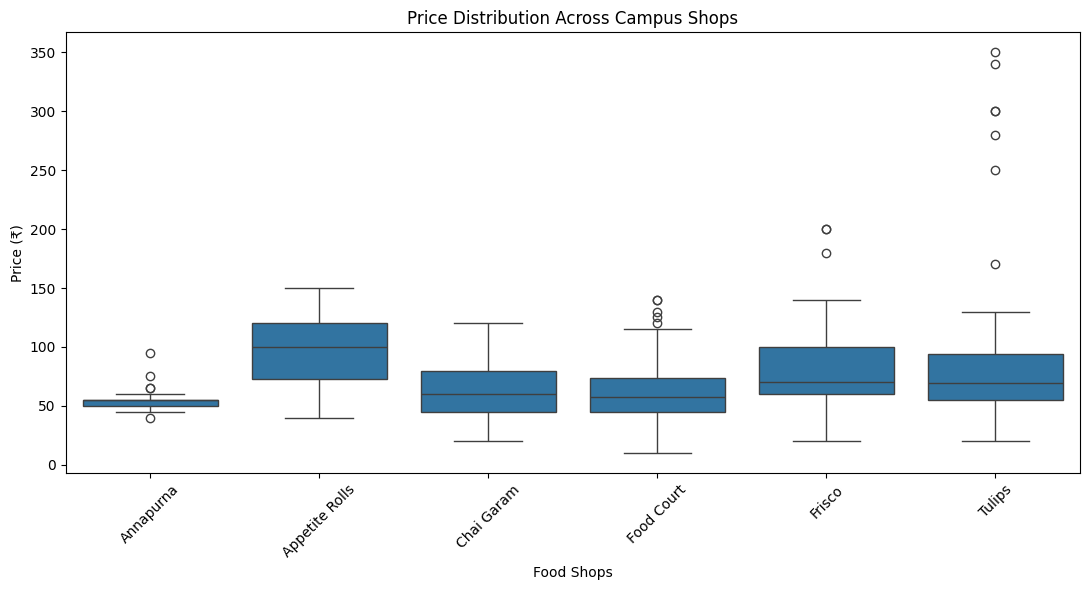

In [14]:

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="Shop Name",
    y="Price"
)

plt.title("Price Distribution Across Campus Shops")
plt.xlabel("Food Shops")
plt.ylabel("Price (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [15]:

print("Shop with Highest Price Variation:")
print(price_variation["Price Standard Deviation"].idxmax())

print("\nShop with Lowest Price Variation:")
print(price_variation["Price Standard Deviation"].idxmin())


Shop with Highest Price Variation:
Tulips

Shop with Lowest Price Variation:
Annapurna


STEP 7 – BUDGET-FRIENDLY SHOP ANALYSIS

In [16]:

# Count affordable items in each shop

budgets = [30, 50, 100]

for budget in budgets:
    print(f"\nItems costing ₹{budget} or less:")

    affordable = df[df["Price"] <= budget]

    display(
        affordable.groupby("Shop Name")["Item to Buy"]
        .count()
        .sort_values(ascending=False)
        .rename("Number of Items")
    )



Items costing ₹30 or less:


Shop Name
Chai Garam    14
Food Court    10
Frisco        10
Tulips         2
Name: Number of Items, dtype: int64


Items costing ₹50 or less:


Shop Name
Food Court        37
Chai Garam        33
Frisco            19
Tulips            12
Annapurna         10
Appetite Rolls     5
Name: Number of Items, dtype: int64


Items costing ₹100 or less:


Shop Name
Chai Garam        94
Food Court        76
Frisco            70
Tulips            41
Annapurna         23
Appetite Rolls    19
Name: Number of Items, dtype: int64

In [17]:

# Cheapest food item in each shop

cheapest_items = df.loc[
    df.groupby("Shop Name")["Price"].idxmin(),
    ["Shop Name", "Item to Buy", "Price"]
]

print("Cheapest Item Available at Each Shop:")
display(cheapest_items.reset_index(drop=True))


Cheapest Item Available at Each Shop:


,Shop Name,Item to Buy,Price
0,Annapurna,Plain Idli - 2 pc,40
1,Appetite Rolls,Single Aloo Roll,40
2,Chai Garam,Black Coffee - Regular,20
3,Food Court,Tandoori Roti (1 pc),10
4,Frisco,Regular Tea,20
5,Tulips,Vanilla Cream Roll,20


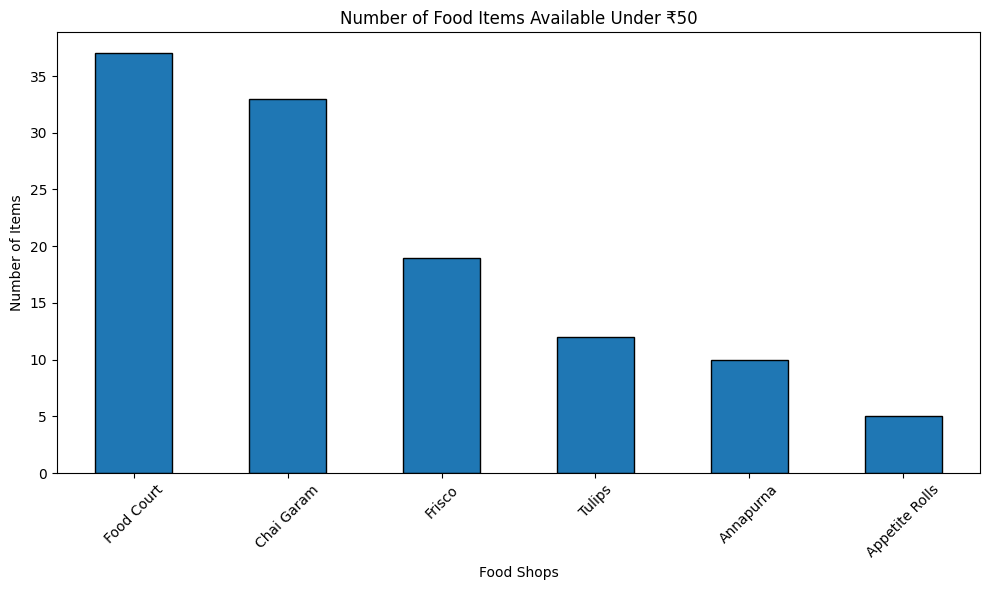

In [18]:

affordable_50 = df[df["Price"] <= 50]

budget_counts = affordable_50["Shop Name"].value_counts()

plt.figure(figsize=(10, 6))

budget_counts.plot(kind="bar", edgecolor="black")

plt.title("Number of Food Items Available Under ₹50")
plt.xlabel("Food Shops")
plt.ylabel("Number of Items")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


STEP 8 – SHOP RANKING AND BUDGET ANALYSIS

In [19]:

# Calculate total items and affordable items in each shop

shop_budget = df.groupby("Shop Name").agg(
    Total_Items=("Item to Buy", "count"),
    Affordable_Items=("Price", lambda x: (x <= 50).sum())
)

shop_budget["Affordable_Percentage"] = (
    shop_budget["Affordable_Items"] /
    shop_budget["Total_Items"] * 100
)

shop_budget = shop_budget.sort_values(
    by="Affordable_Percentage",
    ascending=False
)

print("Shop Ranking Based on Affordable Items:")
display(shop_budget.round(2))


Shop Ranking Based on Affordable Items:


,Total_Items,Affordable_Items,Affordable_Percentage
Shop Name,,,
Food Court,82,37,45.12
Annapurna,23,10,43.48
Chai Garam,98,33,33.67
Tulips,50,12,24.00
Frisco,80,19,23.75
Appetite Rolls,30,5,16.67


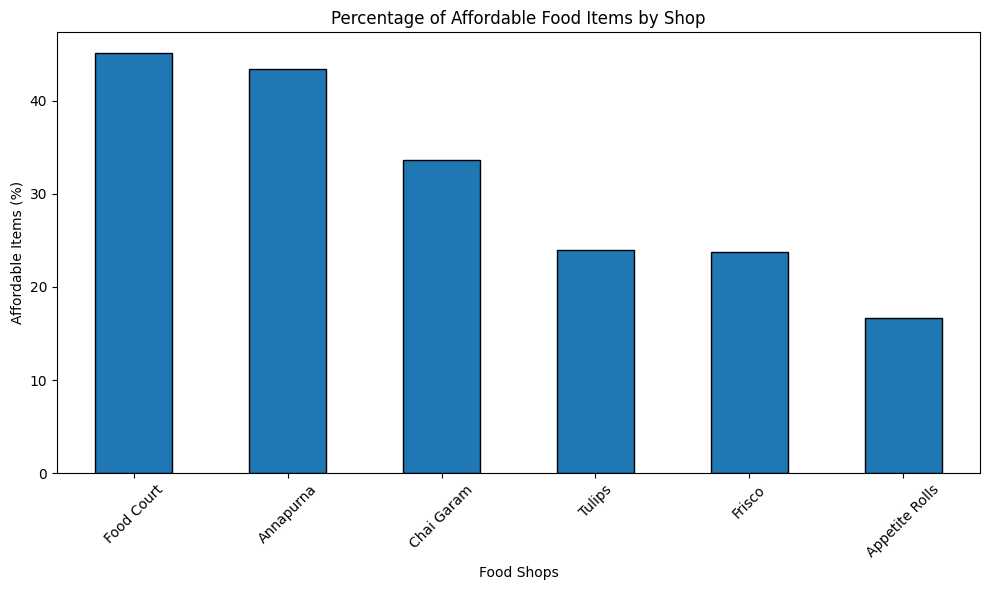

In [20]:

plt.figure(figsize=(10, 6))

shop_budget["Affordable_Percentage"].plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Percentage of Affordable Food Items by Shop")
plt.xlabel("Food Shops")
plt.ylabel("Affordable Items (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [21]:

best_shop = shop_budget["Affordable_Percentage"].idxmax()

print("Best Budget-Friendly Shop:", best_shop)

print(
    "Affordable Items Percentage:",
    round(shop_budget["Affordable_Percentage"].max(), 2), "%"
)


Best Budget-Friendly Shop: Food Court
Affordable Items Percentage: 45.12 %


Best Shop for Each Food Category

In [22]:

# Calculate average price for each category in each shop

category_shop_prices = df.pivot_table(
    index="Category",
    columns="Shop Name",
    values="Price",
    aggfunc="mean"
)

print("Average Price by Category and Shop:")
display(category_shop_prices.round(2))


Average Price by Category and Shop:


Shop Name,Annapurna,Appetite Rolls,Chai Garam,Food Court,Frisco,Tulips
Category,,,,,,
Beverages,NaN,NaN,53.80,18.50,63.24,75.33
Desserts,NaN,NaN,NaN,20.00,60.77,111.29
Fast Food,NaN,94.83,78.25,48.12,90.80,76.12
Main Course,50.00,NaN,NaN,65.88,170.00,100.00
Snacks,NaN,NaN,51.67,36.89,52.50,82.50
Soups,NaN,NaN,30.00,NaN,NaN,NaN
South Indian,55.95,NaN,NaN,69.11,NaN,55.00


In [23]:

# Find the shop offering each category at the lowest average price

best_shop_category = category_shop_prices.idxmin(axis=1)

best_price_category = category_shop_prices.min(axis=1)

best_category_df = pd.DataFrame({
    "Best Shop": best_shop_category,
    "Lowest Average Price": best_price_category
})

print("Best Shop for Each Food Category:")
display(best_category_df.round(2))


Best Shop for Each Food Category:


,Best Shop,Lowest Average Price
Category,,
Beverages,Food Court,18.50
Desserts,Food Court,20.00
Fast Food,Food Court,48.12
Main Course,Annapurna,50.00
Snacks,Food Court,36.89
Soups,Chai Garam,30.00
South Indian,Tulips,55.00


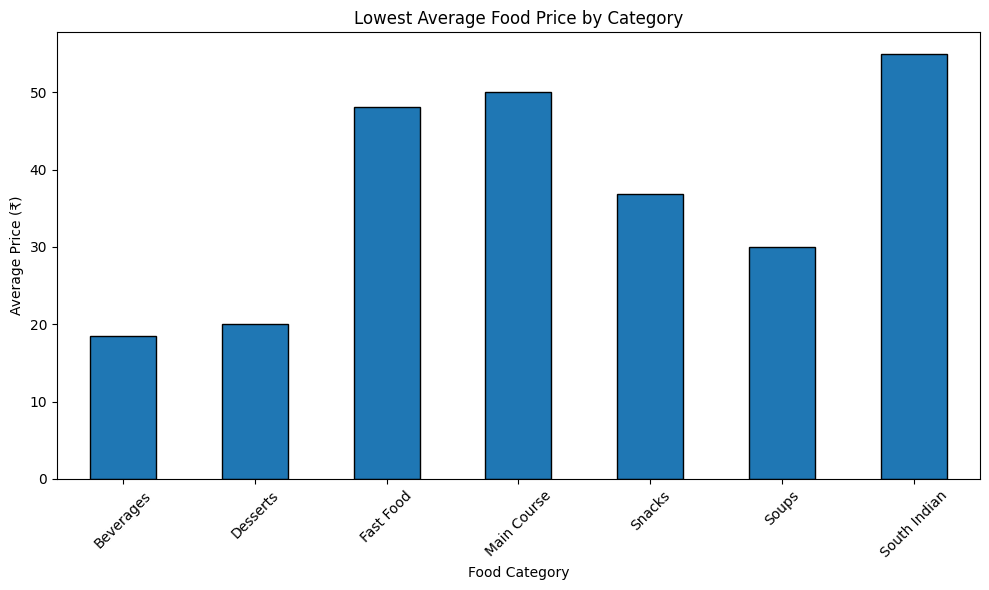

In [24]:

plt.figure(figsize=(10, 6))

best_price_category.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Lowest Average Food Price by Category")
plt.xlabel("Food Category")
plt.ylabel("Average Price (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


STEP 10 – OVERALL CAMPUS FOOD INSIGHTS

In [25]:

# Overall Campus Food Insights

print("========== CAMPUS FOOD INSIGHTS ==========")

# Total food items
print("\nTotal Food Items:", len(df))

# Most popular category
print("\nMost Popular Category:",
      df["Category"].value_counts().idxmax())

# Most expensive food item
expensive_item = df.loc[df["Price"].idxmax()]
print("\nMost Expensive Item:")
print(expensive_item["Item to Buy"],
      "-", expensive_item["Shop Name"],
      "- ₹", expensive_item["Price"])

# Cheapest food item
cheapest_item = df.loc[df["Price"].idxmin()]
print("\nCheapest Item:")
print(cheapest_item["Item to Buy"],
      "-", cheapest_item["Shop Name"],
      "- ₹", cheapest_item["Price"])

# Overall average price
print("\nOverall Average Food Price: ₹",
      round(df["Price"].mean(), 2))

# Most affordable shop
print("\nMost Budget-Friendly Shop: Food Court")

# Shop with maximum food variety
print("\nShop with Maximum Items:",
      df["Shop Name"].value_counts().idxmax())

print("\n========== ANALYSIS COMPLETE ==========")


========== CAMPUS FOOD INSIGHTS ==========

Total Food Items: 363

Most Popular Category: Fast Food

Most Expensive Item:
Red Velvet (Ice Cream Cake) - Tulips - ₹ 350

Cheapest Item:
Tandoori Roti (1 pc) - Food Court - ₹ 10

Overall Average Food Price: ₹ 72.13

Most Budget-Friendly Shop: Food Court

Shop with Maximum Items: Chai Garam

========== ANALYSIS COMPLETE ==========
